In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np
import seaborn as sns
import optuna
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.ensemble import AdaBoostRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor
from catboost import CatBoostRegressor
from math import pi
import shap
import matplotlib.pyplot as plt
from scipy.cluster import hierarchy

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# --------------------------------------------------
# 1. Load data
# --------------------------------------------------
data = pd.read_csv("hpc.csv")

print("Original dataset size:", data.shape)

# --------------------------------------------------
# 2. Remove exact duplicate observations
# --------------------------------------------------
# All columns are considered when identifying exact duplicates
data = data.drop_duplicates(
    keep="first"
).reset_index(drop=True)

print("Dataset size after removing duplicates:", data.shape)
print("Number of removed duplicates:", 2171 - len(data))

# --------------------------------------------------
# 3. Define input variables and target
# --------------------------------------------------
X = data.iloc[:, :-1]
y = data.iloc[:, -1]

# --------------------------------------------------
# 4. Train-test split
# --------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# --------------------------------------------------
# 5. Display dataset statistics
# --------------------------------------------------
print("\nTraining set:", X_train.shape)
print("Testing set :", X_test.shape)

print("\nDescriptive statistics:")
print(data.describe())

Original dataset size: (2171, 9)
Dataset size after removing duplicates: (2142, 9)
Number of removed duplicates: 29

Training set: (1606, 8)
Testing set : (536, 8)

Descriptive statistics:
                 C          BFS           FA            W           SP  \
count  2142.000000  2142.000000  2142.000000  2142.000000  2142.000000   
mean    267.146825    73.648319    66.639122   183.155556     4.601807   
std     110.052345    99.965167    91.089477    33.054944     5.675992   
min      70.000000     0.000000     0.000000   105.000000     0.000000   
25%     180.000000     0.000000     0.000000   159.200000     0.000000   
50%     250.000000     0.000000     0.000000   183.000000     2.800000   
75%     340.000000   140.000000   123.000000   203.500000     7.800000   
max     702.000000   440.000000   544.000000   295.000000    35.100000   

                CA         FAg          Age           CS  
count  2142.000000  2142.00000  2142.000000  2142.000000  
mean    999.452007   742.7

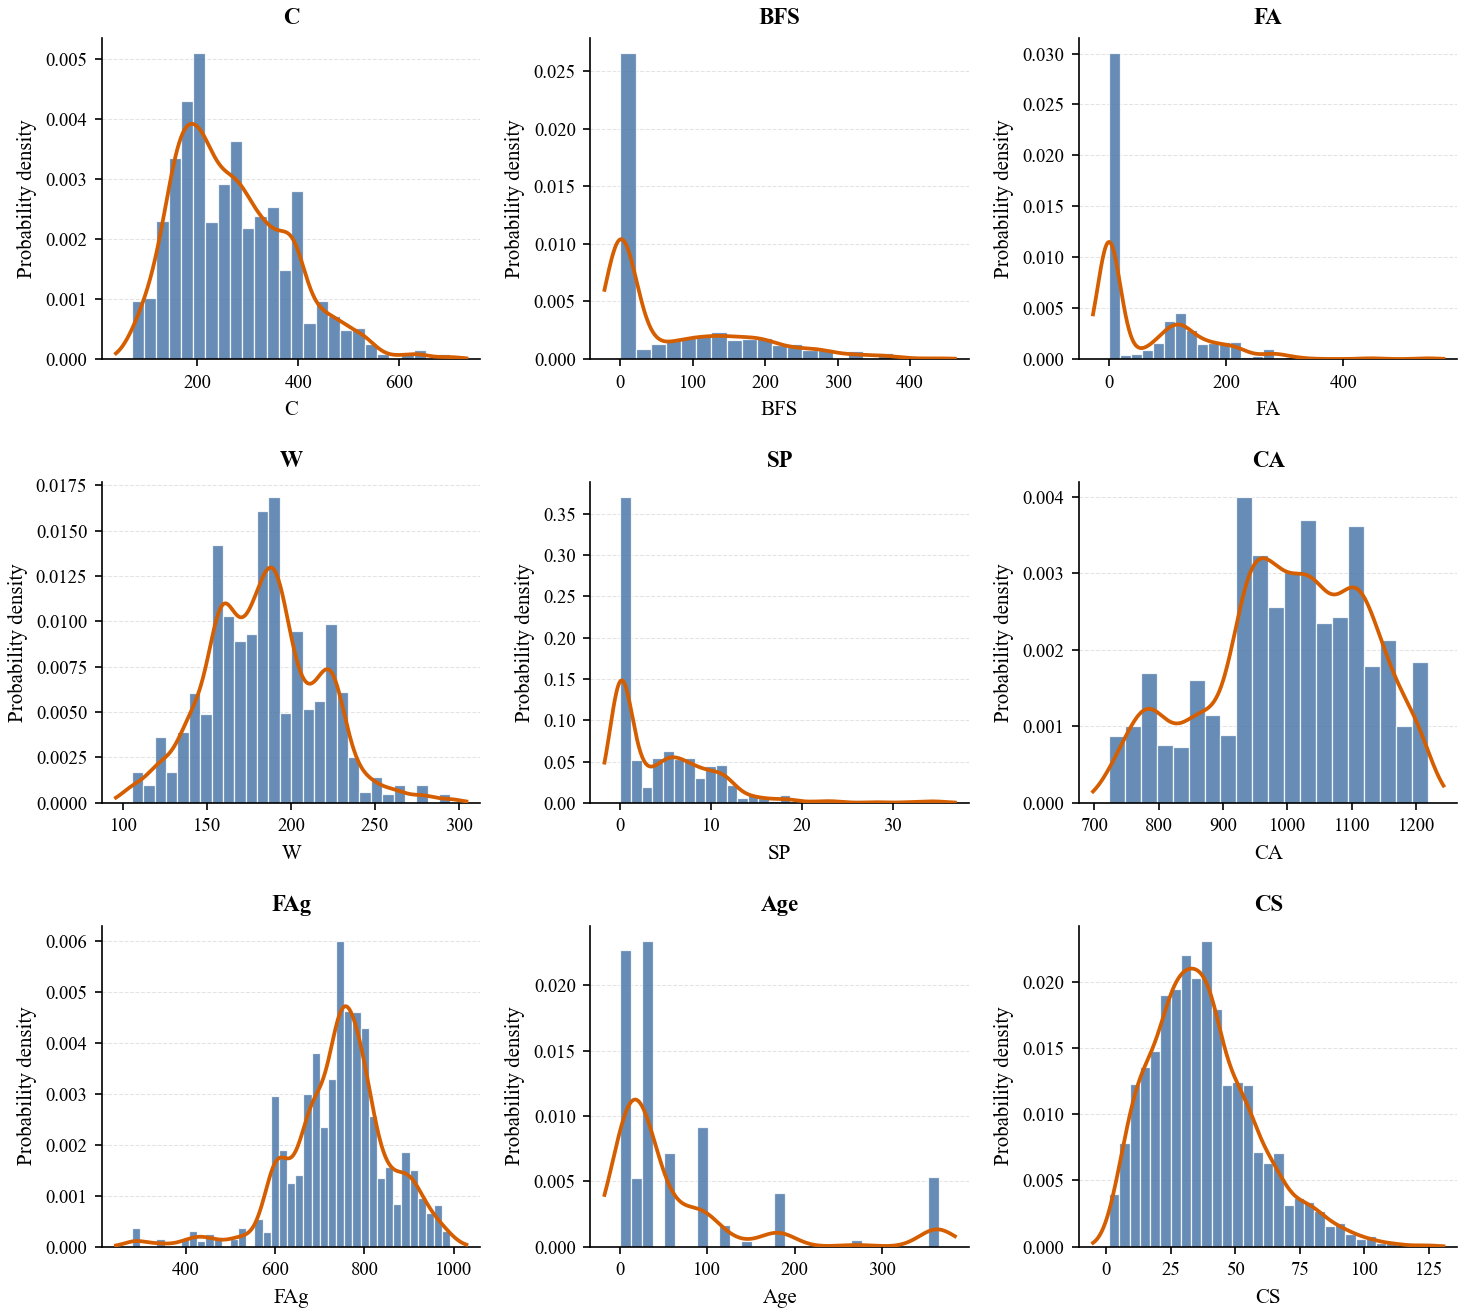

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# ==========================================================
# Publication-quality settings
# ==========================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# ==========================================================
# Variable labels and units
# Replace units with those applicable to your dataset.
# ==========================================================
variable_labels = {
    col: col for col in data.columns
}

# Optional: specify units for variables with known units.
# Example:
# variable_labels = {
#     "C": "Cement (kg/m³)",
#     "W": "Water (kg/m³)",
#     "Age": "Curing age (days)",
#     ...
# }

# ==========================================================
# Prepare the data
# ==========================================================
n_variables = data.shape[1]
ncols = 3
nrows = int(np.ceil(n_variables / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(10, 3.0 * nrows),
    squeeze=False
)
axes = axes.ravel()

hist_color = "#4C78A8"
kde_color = "#D55E00"

for i, col in enumerate(data.columns):
    ax = axes[i]

    # Remove missing and non-finite observations
    values = data[col].to_numpy(dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        ax.set_visible(False)
        continue

    # Histogram: probability density
    ax.hist(
        values,
        bins="auto",
        density=True,
        color=hist_color,
        edgecolor="white",
        linewidth=0.6,
        alpha=0.85
    )

    # KDE: evaluate only when the data support estimation
    if len(values) > 1 and np.std(values) > 0:
        try:
            kde = gaussian_kde(values)
            x_min, x_max = values.min(), values.max()
            spread = x_max - x_min

            # Add a small margin around the observed range
            margin = 0.05 * spread if spread > 0 else 1.0
            xx = np.linspace(
                x_min - margin,
                x_max + margin,
                400
            )

            ax.plot(
                xx,
                kde(xx),
                color=kde_color,
                linewidth=1.8,
                zorder=3
            )
        except (ValueError, np.linalg.LinAlgError):
            pass

    # Titles and labels
    ax.set_title(
        variable_labels.get(col, col),
        loc="center",
        pad=7,
        fontweight="semibold"
    )
    ax.set_xlabel(variable_labels.get(col, col), labelpad=4)
    ax.set_ylabel("Probability density", labelpad=4)

    # Improve readability
    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.5,
        alpha=0.35
    )
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.margins(x=0.04)

# Remove unused panels
for j in range(n_variables, len(axes)):
    fig.delaxes(axes[j])

fig.tight_layout(pad=1.2, h_pad=1.5, w_pad=1.2)

# Save publication-quality outputs
fig.savefig("Figure_Distributions.png", dpi=600)
fig.savefig("Figure_Distributions.pdf", format="pdf")

plt.show()

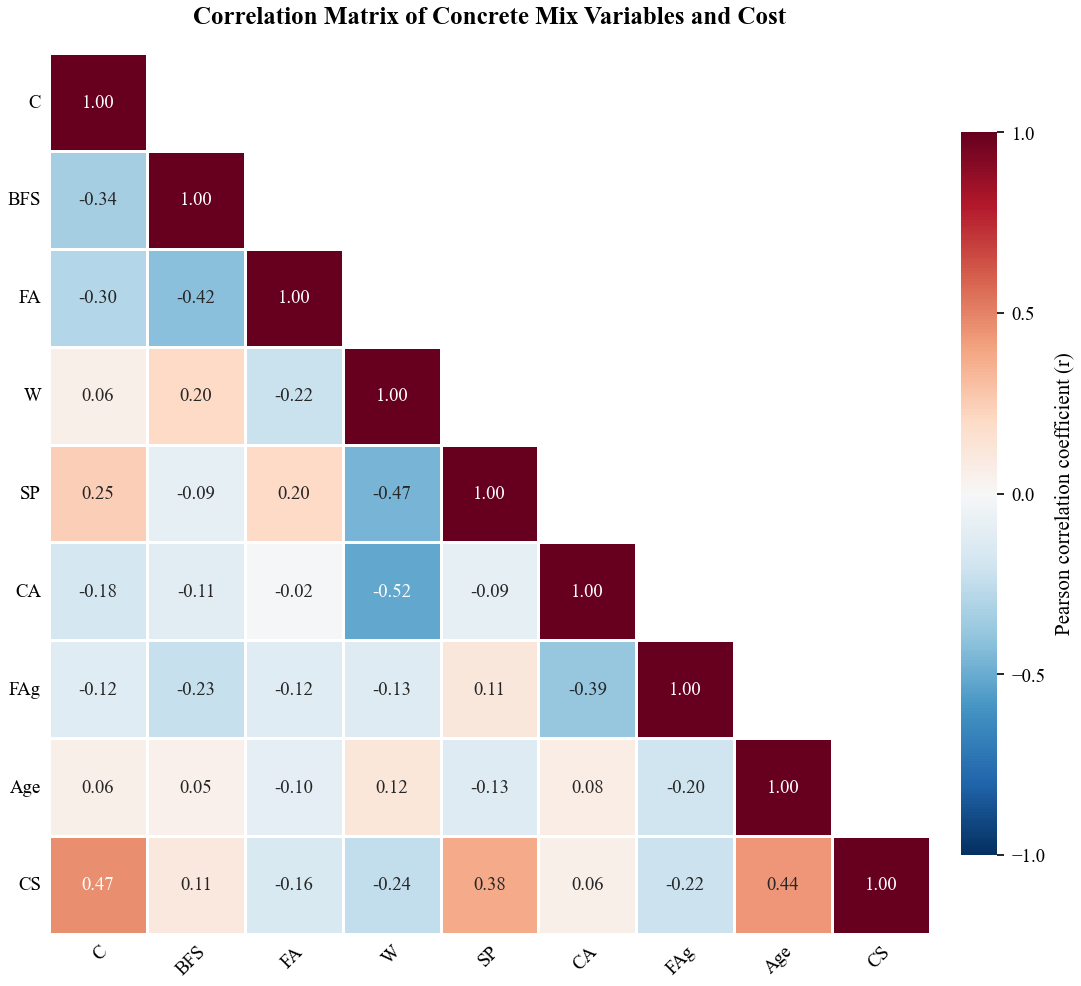

In [5]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================================
# Publication-quality settings
# ==========================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# ==========================================================
# Calculate Pearson correlation coefficients
# ==========================================================
corr = data.corr(method="pearson", numeric_only=True)

# Mask the upper triangle to reduce visual clutter
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

# Figure size adapts to the number of variables
n = len(corr.columns)
fig_size = max(8, 0.85 * n)

fig, ax = plt.subplots(
    figsize=(fig_size, fig_size * 0.82),
    constrained_layout=True
)

# Diverging colour map centred at zero
sns.heatmap(
    corr,
    mask=mask,
    ax=ax,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 9},
    linewidths=0.5,
    linecolor="white",
    cbar=True,
    cbar_kws={
        "label": "Pearson correlation coefficient (r)",
        "shrink": 0.82,
        "pad": 0.03,
        "ticks": [-1, -0.5, 0, 0.5, 1]
    }
)

ax.set_title(
    "Correlation Matrix of Concrete Mix Variables and Cost",
    pad=14,
    fontweight="semibold"
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor"
)
ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0
)

ax.tick_params(axis="both", length=0, pad=4)

# Save high-resolution raster and vector versions
fig.savefig("Figure_Correlation_Matrix.png", dpi=600)
fig.savefig("Figure_Correlation_Matrix.pdf", format="pdf")

plt.show()

C:\Users\Mohsen\AppData\Local\Temp\ipykernel_9352\782711837.py:8: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  clustering = sch.linkage(dist_matrix, method="complete")


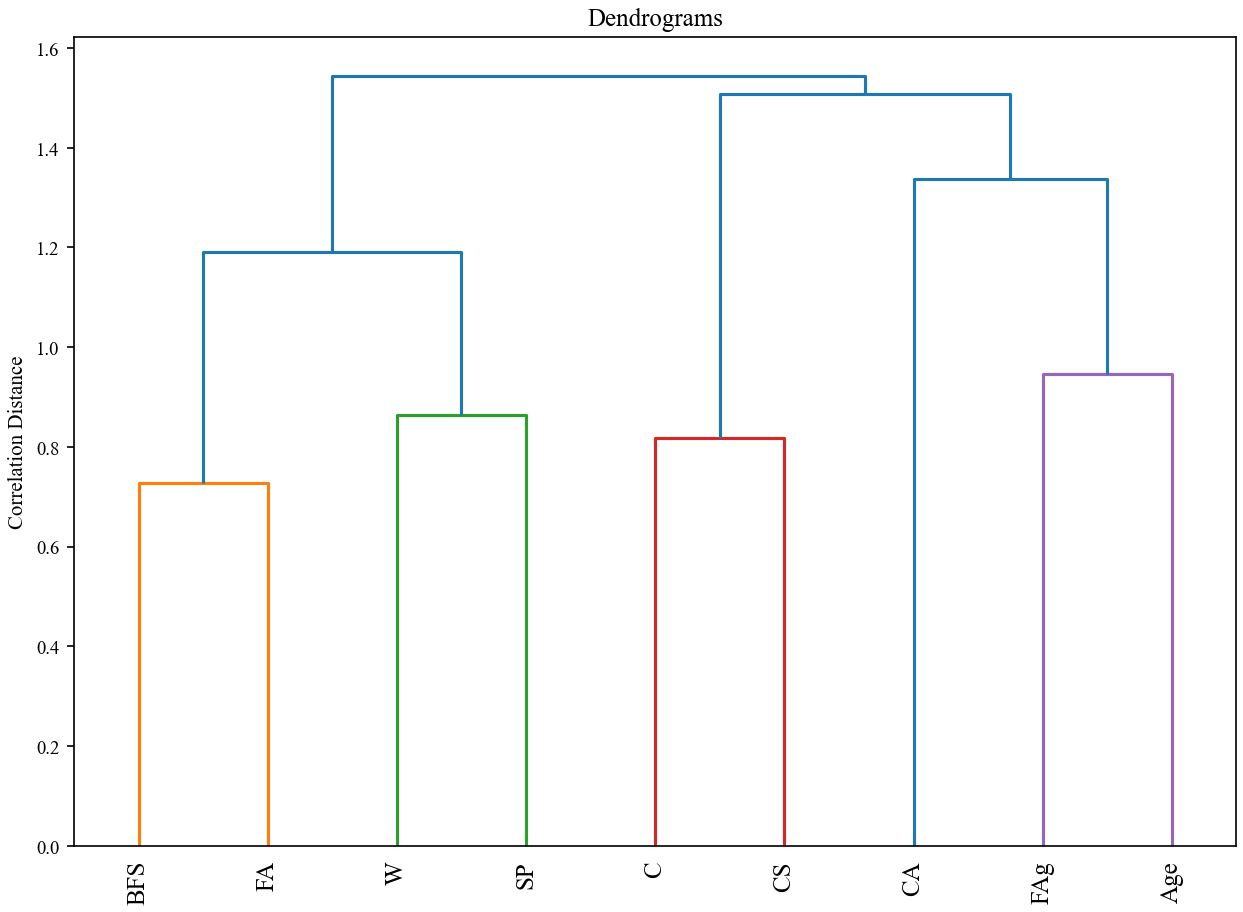

In [6]:
# Dendrograms
correlation_matrix = data.corr()

correlation_matrix = np.corrcoef(correlation_matrix)
correlation_matrix = np.abs(correlation_matrix)
dist_matrix = 1 - correlation_matrix
import scipy.cluster.hierarchy as sch
clustering = sch.linkage(dist_matrix, method="complete")
plt.figure(figsize=(10, 7))
plt.title("Dendrograms")
dend = hierarchy.dendrogram(clustering, labels=data.columns)
# Rotate labels for better readability
plt.xticks(rotation=90)
# Increase label size for better visibility
plt.tick_params(axis='x', which='major', labelsize=12)
plt.ylabel('Correlation Distance')
plt.show()

In [ ]:
# Tuning the hyperparameters of the AdaBoostRegressor model

def objective(trial):

    base_estimator = DecisionTreeRegressor(
        max_depth=trial.suggest_int("max_depth", 1, 10),
        min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
        random_state=42
    )

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 1.0, log=True),
        "loss": trial.suggest_categorical("loss", ["linear", "square", "exponential"]),
        "estimator": base_estimator,
        "random_state": 42
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = AdaBoostRegressor(**params)
        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)
        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")

In [18]:
# Evaluating the AdaBoostRegressor model
final_model = AdaBoostRegressor(
    n_estimators=980,
    learning_rate= 0.9666320006407733,
    loss="square",
    random_state=42,
    estimator=DecisionTreeRegressor(
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    )
)

final_model.fit(X_train, y_train)
models = {}
models['AdaBoostRegressor'] = final_model  
y_pred = final_model.predict(X_test)
y_AdaBoostRegressor=y_pred
model_AdaBoostRegressor=final_model


r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

(0.9348682711551929,
 np.float64(0.9685623204760508),
 24.4292167319779,
 np.float64(4.942592106575041),
 3.5755652116302334)

In [ ]:
# Tuning the hyperparameters of the RandomForestRegressor

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1500),
        "max_depth": trial.suggest_int("max_depth", 3, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        
        "bootstrap": trial.suggest_categorical("bootstrap", [True, False]),
        "random_state": 42,
        "n_jobs": -1
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = RandomForestRegressor(**params)
        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)
        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")


In [19]:
# Evaluating the RandomForestRegressor model
final_model = RandomForestRegressor(
    n_estimators=419,
    max_depth=17,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='log2',
    bootstrap=False,
    random_state=42,    
)

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_RandomForestRegressor=y_pred
model_RandomForestRegressor=final_model

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

(0.9336987440543497,
 np.float64(0.9686006009409567),
 24.867875915868094,
 np.float64(4.9867700885310615),
 3.5352280300781675)

In [ ]:
# Tuning the hyperparameters of the SVR

def objective(trial):
    params = {
        "C": trial.suggest_float("C", 0.1, 100, log=True),
        "epsilon": trial.suggest_float("epsilon", 0.001, 1.0, log=True),
        "gamma": trial.suggest_float("gamma", 1e-4, 1e-1, log=True),
        "kernel": trial.suggest_categorical("kernel", ["rbf", "poly", "sigmoid"])
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("svr", SVR(**params))
        ])

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        y_SVR=y_pred

        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")


In [20]:
# Evaluating the SVR model

final_model = Pipeline([
            ("scaler", StandardScaler()),
            ("svr", SVR(C=77.61384807907002, 
                        epsilon=0.3461051805988799,
                        gamma=0.023703450980572367,
                        kernel='rbf'))
        ])

final_model.fit(X_train, y_train)
model_SVR=final_model
y_pred = final_model.predict(X_test)
y_SVR = y_pred

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

(0.8190117599035943,
 np.float64(0.9050953834248249),
 67.88397946244388,
 np.float64(8.239173469617196),
 6.299766825020302)

In [ ]:
# Tuning the hyperparameters of the XGBRegressor

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1500),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "subsample": trial.suggest_float("subsample", 0.3, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
        "random_state": 42,
        "n_jobs": -1
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = XGBRegressor(**params)
        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)
        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")


In [11]:
# Evaluating the XGBRegressor model

final_model = XGBRegressor(
    n_estimators=917,
    max_depth=4,
    gamma= 1.8911007904659085,
    colsample_bytree= 0.8554485707648913,
    subsample= 0.8797561364531741,
    min_child_weight=4,
    learning_rate= 0.2571174366634496,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)
final_model.save_model("xgb_model.json")

model_XGBRegressor=final_model
y_pred = final_model.predict(X_test)
y_XGBRegressor=y_pred

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

TypeError: `_estimator_type` undefined.  Please use appropriate mixin to define estimator type.

In [9]:
# final_model.save_model("xgb_model.json")
final_model.save_model("xgb_model", format='json')


TypeError: XGBModel.save_model() got an unexpected keyword argument 'format'

In [ ]:
# Tuning the hyperparameters of the ANN

def objective(trial):
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden_sizes = []

    for i in range(n_layers):
        hidden_sizes.append(trial.suggest_int(f"n_units_layer_{i}", 16, 256))

    hidden_layer_sizes = tuple(hidden_sizes)

    params = {
        "hidden_layer_sizes": hidden_layer_sizes,
        "activation": trial.suggest_categorical("activation", ["relu", "tanh", "logistic"]),
        "solver": trial.suggest_categorical("solver", ["adam", "lbfgs"]),
        "alpha": trial.suggest_float("alpha", 1e-6, 1e-1, log=True),
        "learning_rate_init": trial.suggest_float("learning_rate_init", 1e-4, 1e-1, log=True),
        "max_iter": 1000,
        "random_state": 42
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("ann", MLPRegressor(**params))
        ])

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")


In [22]:
# Evaluating the ANN model


final_model = Pipeline([
            ("scaler", StandardScaler()),
            ("ann", MLPRegressor(
                hidden_layer_sizes= (143,229,69),
                activation= 'relu',
                solver= 'lbfgs',
                alpha= 4.753647410422033e-06,
                learning_rate_init= 0.0152548399894833,
                max_iter= 1000,
                random_state= 42))
        ])
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
y_MLPRegressor=y_pred
model_MLPRegressor=final_model


r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

c:\Users\Mohsen\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


(0.9465404546180962,
 np.float64(0.9734462286723908),
 20.051284430655187,
 np.float64(4.4778660576948015),
 3.0699491477972636)

In [ ]:
# Tuning the hyperparameters of the CatBoostRegressor

def objective(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 200, 1500),
        "depth": trial.suggest_int("depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 10),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 5),
        "random_strength": trial.suggest_float("random_strength", 0, 2),
        "border_count": trial.suggest_int("border_count", 32, 255),
        "loss_function": "RMSE",
        "random_seed": 42,
        "verbose": 0
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = CatBoostRegressor(**params)
        model.fit(X_tr, y_tr, eval_set=(X_val, y_val), verbose=0)

        y_pred = model.predict(X_val)
        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")


In [23]:
# Evaluating the CatBoostRegressor model


final_model = CatBoostRegressor(
    iterations= 521,
    depth= 4,
    learning_rate= 0.1938872791139316,
    l2_leaf_reg= 2.6054094641102856,
    bagging_temperature= 4.063623701027753,
    random_strength= 0.037516935694481446,
    border_count= 104,
    random_state=42
)

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_CatBoostRegressor=y_pred
model_CatBoostRegressor = final_model

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

0:	learn: 18.4627658	total: 6.32ms	remaining: 3.29s
1:	learn: 16.8148013	total: 9.41ms	remaining: 2.44s
2:	learn: 15.3906419	total: 11.8ms	remaining: 2.03s
3:	learn: 14.1523128	total: 15.5ms	remaining: 2s
4:	learn: 13.1283765	total: 18.4ms	remaining: 1.9s
5:	learn: 12.3424211	total: 21ms	remaining: 1.8s
6:	learn: 11.6081042	total: 23.9ms	remaining: 1.75s
7:	learn: 10.9486523	total: 26.2ms	remaining: 1.68s
8:	learn: 10.3579560	total: 28.6ms	remaining: 1.63s
9:	learn: 9.8971540	total: 53.8ms	remaining: 2.75s
10:	learn: 9.5608895	total: 56ms	remaining: 2.6s
11:	learn: 9.1862889	total: 58.4ms	remaining: 2.48s
12:	learn: 8.8961925	total: 61.6ms	remaining: 2.41s
13:	learn: 8.6749850	total: 64ms	remaining: 2.32s
14:	learn: 8.4183506	total: 66.1ms	remaining: 2.23s
15:	learn: 8.1772054	total: 68.2ms	remaining: 2.15s
16:	learn: 8.0175960	total: 70.3ms	remaining: 2.08s
17:	learn: 7.7881760	total: 72.8ms	remaining: 2.03s
18:	learn: 7.6018830	total: 81.3ms	remaining: 2.15s
19:	learn: 7.4671362	tota

(0.963444393910823,
 np.float64(0.9817357384810302),
 13.711056650272141,
 np.float64(3.702844399954195),
 2.718464228918128)

In [24]:
models = {
    "XGBoost": model_XGBRegressor,
    "ANN": model_MLPRegressor,
    "SVR": model_SVR,
    "AdaBoost": model_AdaBoostRegressor,
    "RF": model_RandomForestRegressor,
    "CatBoost": model_CatBoostRegressor
}

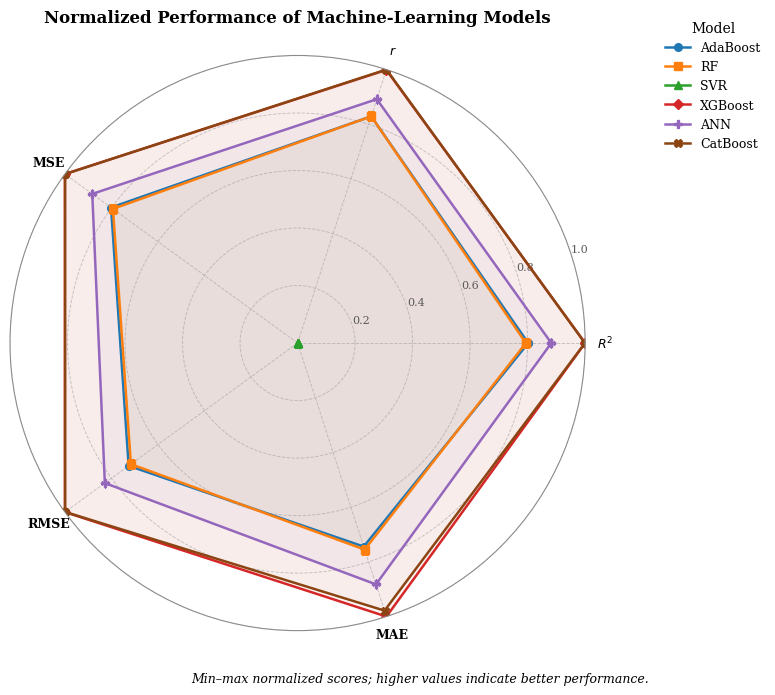

Normalized scores (higher is better):
Model               R2         r       MSE      RMSE       MAE
AdaBoost         0.802     0.829     0.802     0.726     0.744
RF               0.794     0.829     0.794     0.716     0.755
SVR              0.000     0.000     0.000     0.000     0.000
XGBoost          1.000     0.999     1.000     1.000     1.000
ANN              0.882     0.892     0.882     0.828     0.882
CatBoost         0.999     1.000     0.999     0.999     0.978


In [27]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Original performance metrics
# --------------------------------------------------
data = {
    "AdaBoost": {
        "R2": 0.9349, "r": 0.9686, "MSE": 24.4292,
        "RMSE": 4.9426, "MAE": 3.5756
    },
    "RF": {
        "R2": 0.9337, "r": 0.9686, "MSE": 24.8679,
        "RMSE": 4.9868, "MAE": 3.5352
    },
    "SVR": {
        "R2": 0.8190, "r": 0.9051, "MSE": 67.8840,
        "RMSE": 8.2392, "MAE": 6.2998
    },
    "XGBoost": {
        "R2": 0.9635, "r": 0.9816, "MSE": 13.6811,
        "RMSE": 3.6988, "MAE": 2.6394
    },
    "ANN": {
        "R2": 0.9465, "r": 0.9734, "MSE": 20.0513,
        "RMSE": 4.4779, "MAE": 3.0699
    },
    "CatBoost": {
        "R2": 0.9634, "r": 0.9817, "MSE": 13.7111,
        "RMSE": 3.7028, "MAE": 2.7185
    }
}

metrics = ["R2", "r", "MSE", "RMSE", "MAE"]
metric_labels = ["$R^2$", "$r$", "MSE", "RMSE", "MAE"]
lower_is_better = {"MSE", "RMSE", "MAE"}

# --------------------------------------------------
# Min-max normalization
# Higher normalized score always means better performance
# --------------------------------------------------
normalized_data = {}

for metric in metrics:
    metric_values = np.array(
        [data[model][metric] for model in data],
        dtype=float
    )

    min_val = metric_values.min()
    max_val = metric_values.max()

    if np.isclose(max_val, min_val):
        scaled = np.ones_like(metric_values)
    elif metric in lower_is_better:
        scaled = (max_val - metric_values) / (max_val - min_val)
    else:
        scaled = (metric_values - min_val) / (max_val - min_val)

    for model, score in zip(data.keys(), scaled):
        normalized_data.setdefault(model, {})[metric] = score

# --------------------------------------------------
# Radar chart
# --------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

n_metrics = len(metrics)
angles = np.linspace(0, 2 * np.pi, n_metrics, endpoint=False)
closed_angles = np.r_[angles, angles[0]]

colors = {
    "AdaBoost": "tab:blue",
    "RF": "tab:orange",
    "SVR": "tab:green",
    "XGBoost": "tab:red",
    "ANN": "tab:purple",
    "CatBoost": "saddlebrown"
}

markers = {
    "AdaBoost": "o",
    "RF": "s",
    "SVR": "^",
    "XGBoost": "D",
    "ANN": "P",
    "CatBoost": "X"
}

fig, ax = plt.subplots(
    figsize=(8.5, 7.2),
    subplot_kw={"polar": True}
)

for model in data:
    # Build a new list; do not mutate normalized_data
    scores = [normalized_data[model][m] for m in metrics]
    closed_scores = scores + [scores[0]]

    ax.plot(
        closed_angles,
        closed_scores,
        color=colors[model],
        linewidth=1.8,
        marker=markers[model],
        markersize=5.5,
        label=model
    )

    ax.fill(
        closed_angles,
        closed_scores,
        color=colors[model],
        alpha=0.045
    )

# Metric labels and scale
ax.set_xticks(angles)
ax.set_xticklabels(metric_labels, fontweight="semibold")

ax.set_ylim(0, 1.0)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(
    ["0.2", "0.4", "0.6", "0.8", "1.0"],
    fontsize=8,
    color="0.35"
)
ax.set_rlabel_position(18)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.65,
    alpha=0.55,
    color="0.6"
)
ax.spines["polar"].set_color("0.55")
ax.spines["polar"].set_linewidth(0.8)

ax.set_title(
    "Normalized Performance of Machine-Learning Models",
    fontsize=12,
    fontweight="semibold",
    pad=24
)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.12, 1.08),
    title="Model",
    frameon=False,
    ncol=1,
    handlelength=2.0
)

fig.text(
    0.5, 0.035,
    "Min–max normalized scores; higher values indicate better performance.",
    ha="center",
    fontsize=9,
    style="italic"
)

fig.tight_layout(rect=[0, 0.06, 0.86, 1])

fig.savefig(
    "Figure_Radar_Normalized_Performance.png",
    dpi=600,
    bbox_inches="tight"
)
fig.savefig(
    "Figure_Radar_Normalized_Performance.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# Print normalized scores for verification
# --------------------------------------------------
print("Normalized scores (higher is better):")
print(f"{'Model':<12}" + "".join(f"{m:>10}" for m in metrics))

for model in data:
    print(
        f"{model:<12}"
        + "".join(
            f"{normalized_data[model][m]:>10.3f}"
            for m in metrics
        )
    )

c:\Users\Mohsen\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\Mohsen\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_re

0:	learn: 18.4102454	total: 1.62ms	remaining: 843ms
1:	learn: 16.7694838	total: 3.04ms	remaining: 789ms
2:	learn: 15.3568948	total: 4.43ms	remaining: 765ms
3:	learn: 14.2393786	total: 5.86ms	remaining: 757ms
4:	learn: 13.2670647	total: 7.25ms	remaining: 748ms
5:	learn: 12.3733097	total: 9.08ms	remaining: 779ms
6:	learn: 11.7141735	total: 11.1ms	remaining: 816ms
7:	learn: 11.0934346	total: 12.6ms	remaining: 808ms
8:	learn: 10.5692866	total: 14ms	remaining: 795ms
9:	learn: 10.0856806	total: 15.3ms	remaining: 783ms
10:	learn: 9.7131270	total: 16.6ms	remaining: 772ms
11:	learn: 9.3531879	total: 18ms	remaining: 764ms
12:	learn: 9.0601298	total: 19.4ms	remaining: 756ms
13:	learn: 8.7306871	total: 20.7ms	remaining: 749ms
14:	learn: 8.5216673	total: 22.4ms	remaining: 755ms
15:	learn: 8.2647579	total: 24.7ms	remaining: 780ms
16:	learn: 8.0170712	total: 26.5ms	remaining: 787ms
17:	learn: 7.8162986	total: 27.9ms	remaining: 780ms
18:	learn: 7.6609915	total: 29.3ms	remaining: 774ms
19:	learn: 7.531

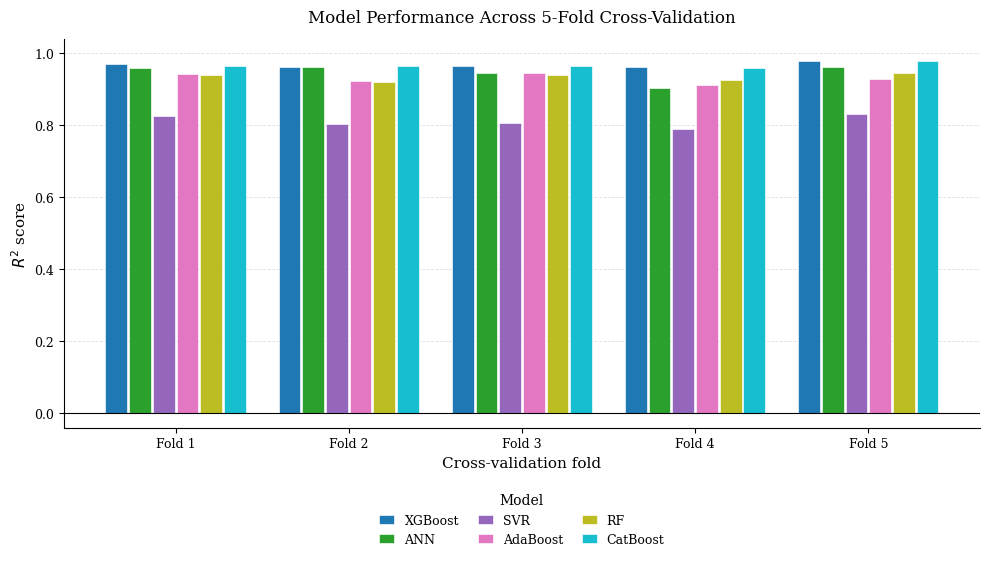

In [26]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score

# Reproducible 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

model_names = list(models.keys())
fold_r2 = {name: [] for name in model_names}

# Evaluate each model across the same five folds
for model_name, model in models.items():
    for train_idx, test_idx in kf.split(X, y):
        X_train1 = X.iloc[train_idx]
        X_test1 = X.iloc[test_idx]
        y_train1 = y.iloc[train_idx]
        y_test1 = y.iloc[test_idx]

        # Clone the estimator to avoid carrying fitted state between folds
        from sklearn.base import clone
        model_fold = clone(model)

        model_fold.fit(X_train1, y_train1)
        y_pred1 = model_fold.predict(X_test1)

        fold_r2[model_name].append(
            r2_score(y_test1, y_pred1)
        )

# Publication-style plotting
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

n_folds = 5
n_models = len(model_names)
x = np.arange(n_folds)

group_width = 0.82
bar_width = group_width / n_models
colors = plt.get_cmap("tab10")(
    np.linspace(0, 1, n_models)
)

fig, ax = plt.subplots(figsize=(10, 5.8))

for i, model_name in enumerate(model_names):
    # Center all model bars around each fold position
    offsets = (
        i - (n_models - 1) / 2
    ) * bar_width

    ax.bar(
        x + offsets,
        fold_r2[model_name],
        width=bar_width * 0.92,
        label=model_name,
        color=colors[i],
        edgecolor="white",
        linewidth=0.45
    )

# Labels and axes
ax.set_xlabel("Cross-validation fold")
ax.set_ylabel(r"$R^2$ score")
ax.set_title(
    r"Model Performance Across 5-Fold Cross-Validation",
    pad=12
)

ax.set_xticks(x)
ax.set_xticklabels([f"Fold {i}" for i in range(1, n_folds + 1)])

# Set y-axis limits using all observed scores, including negative values
all_scores = np.array([
    score
    for name in model_names
    for score in fold_r2[name]
], dtype=float)

y_min = min(0, np.nanmin(all_scores))
y_max = max(1, np.nanmax(all_scores))
padding = max(0.04 * (y_max - y_min), 0.03)

ax.set_ylim(y_min - padding, y_max + padding)

ax.axhline(0, color="black", linewidth=0.8)
ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.4)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Model",
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    frameon=False,
    columnspacing=1.5,
    handlelength=1.2
)

fig.tight_layout()

# High-resolution raster and vector outputs
fig.savefig(
    "Figure_CV_R2_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)
fig.savefig(
    "Figure_CV_R2_Comparison.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

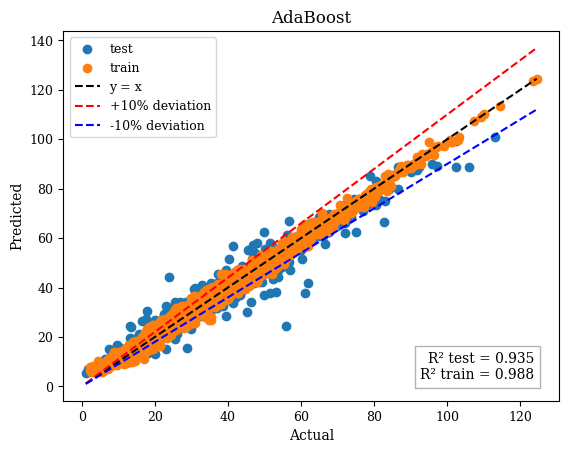

In [28]:
# Comparison of actual and predicted values for both training and testing datasets.


final_model = model_AdaBoostRegressor
y_pred = final_model.predict(X_test)

r2_test = r2_score(y_test, y_AdaBoostRegressor)
r2_train = r2_score(y_train, final_model.predict(X_train))

plt.scatter(y_test, y_pred, label='test')
plt.scatter(y_train, final_model.predict(X_train), label='train')

min_val = min(min(y_test), min(y_train))
max_val = max(max(y_test), max(y_train))
x_vals = np.linspace(min_val, max_val, 100)

plt.plot(x_vals, x_vals, 'k--', label='y = x')

plt.plot(x_vals, x_vals * 1.10, 'r--', label='+10% deviation')
plt.plot(x_vals, x_vals * 0.90, 'b--', label='-10% deviation')

textstr = f'R² test = {r2_test:.3f}\nR² train = {r2_train:.3f}'
plt.text(0.95, 0.05, textstr, transform=plt.gca().transAxes,
         fontsize=10, verticalalignment='bottom', horizontalalignment='right',
         bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray'))

plt.legend()
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('AdaBoost')
plt.show()

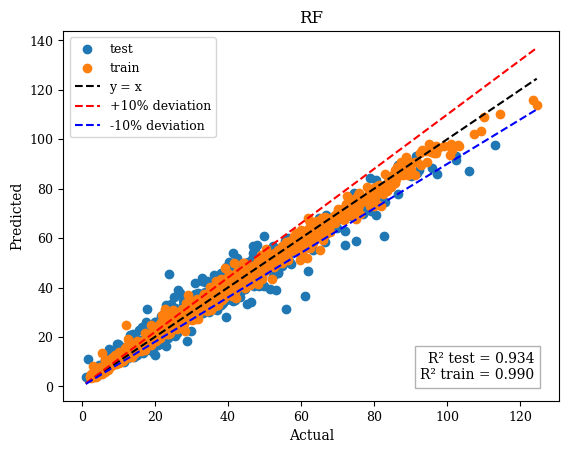

In [31]:
# Comparison of actual and predicted values for both training and testing datasets.


final_model = model_RandomForestRegressor
y_pred = final_model.predict(X_test)

r2_test = r2_score(y_test, y_RandomForestRegressor)
r2_train = r2_score(y_train, final_model.predict(X_train))

plt.scatter(y_test, y_pred, label='test')
plt.scatter(y_train, final_model.predict(X_train), label='train')

min_val = min(min(y_test), min(y_train))
max_val = max(max(y_test), max(y_train))
x_vals = np.linspace(min_val, max_val, 100)

plt.plot(x_vals, x_vals, 'k--', label='y = x')

plt.plot(x_vals, x_vals * 1.10, 'r--', label='+10% deviation')
plt.plot(x_vals, x_vals * 0.90, 'b--', label='-10% deviation')

textstr = f'R² test = {r2_test:.3f}\nR² train = {r2_train:.3f}'
plt.text(0.95, 0.05, textstr, transform=plt.gca().transAxes,
         fontsize=10, verticalalignment='bottom', horizontalalignment='right',
         bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray'))

plt.legend()
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('RF')
plt.show()

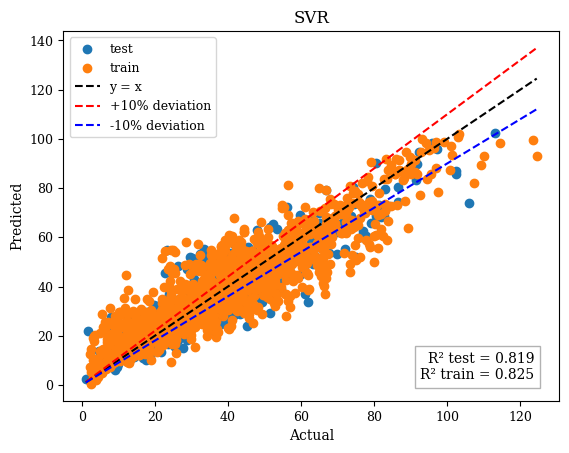

In [32]:
# Comparison of actual and predicted values for both training and testing datasets.


final_model = model_SVR
y_pred = final_model.predict(X_test)

r2_test = r2_score(y_test, y_SVR)
r2_train = r2_score(y_train, final_model.predict(X_train))

plt.scatter(y_test, y_pred, label='test')
plt.scatter(y_train, final_model.predict(X_train), label='train')

min_val = min(min(y_test), min(y_train))
max_val = max(max(y_test), max(y_train))
x_vals = np.linspace(min_val, max_val, 100)

plt.plot(x_vals, x_vals, 'k--', label='y = x')

plt.plot(x_vals, x_vals * 1.10, 'r--', label='+10% deviation')
plt.plot(x_vals, x_vals * 0.90, 'b--', label='-10% deviation')

textstr = f'R² test = {r2_test:.3f}\nR² train = {r2_train:.3f}'
plt.text(0.95, 0.05, textstr, transform=plt.gca().transAxes,
         fontsize=10, verticalalignment='bottom', horizontalalignment='right',
         bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray'))

plt.legend()
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('SVR')
plt.show()

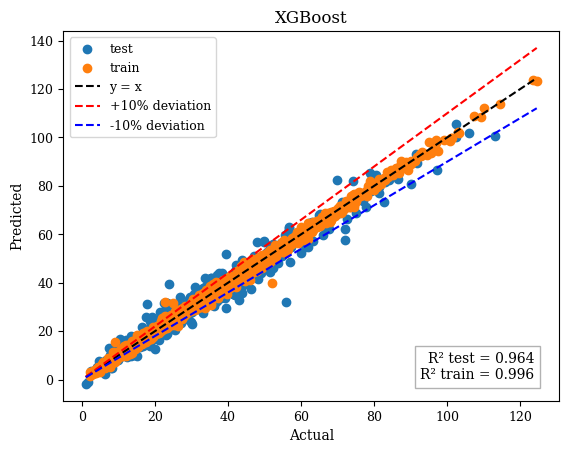

In [33]:
# Comparison of actual and predicted values for both training and testing datasets.


final_model = model_XGBRegressor
y_pred = final_model.predict(X_test)

r2_test = r2_score(y_test, y_XGBRegressor)
r2_train = r2_score(y_train, final_model.predict(X_train))

plt.scatter(y_test, y_pred, label='test')
plt.scatter(y_train, final_model.predict(X_train), label='train')

min_val = min(min(y_test), min(y_train))
max_val = max(max(y_test), max(y_train))
x_vals = np.linspace(min_val, max_val, 100)

plt.plot(x_vals, x_vals, 'k--', label='y = x')

plt.plot(x_vals, x_vals * 1.10, 'r--', label='+10% deviation')
plt.plot(x_vals, x_vals * 0.90, 'b--', label='-10% deviation')

textstr = f'R² test = {r2_test:.3f}\nR² train = {r2_train:.3f}'
plt.text(0.95, 0.05, textstr, transform=plt.gca().transAxes,
         fontsize=10, verticalalignment='bottom', horizontalalignment='right',
         bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray'))

plt.legend()
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('XGBoost')
plt.show()

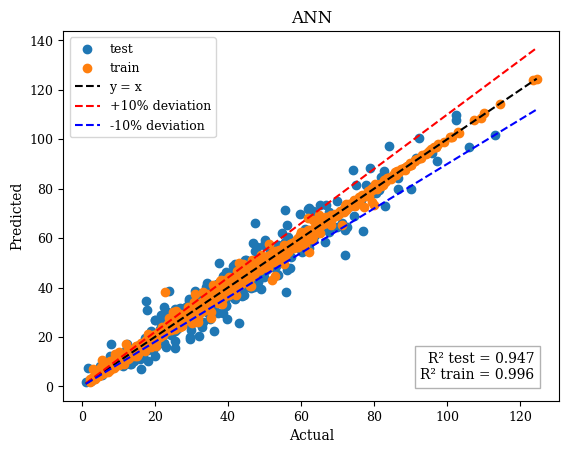

In [34]:
# Comparison of actual and predicted values for both training and testing datasets.


final_model = model_MLPRegressor
y_pred = final_model.predict(X_test)

r2_test = r2_score(y_test, y_MLPRegressor)
r2_train = r2_score(y_train, final_model.predict(X_train))

plt.scatter(y_test, y_pred, label='test')
plt.scatter(y_train, final_model.predict(X_train), label='train')

min_val = min(min(y_test), min(y_train))
max_val = max(max(y_test), max(y_train))
x_vals = np.linspace(min_val, max_val, 100)

plt.plot(x_vals, x_vals, 'k--', label='y = x')

plt.plot(x_vals, x_vals * 1.10, 'r--', label='+10% deviation')
plt.plot(x_vals, x_vals * 0.90, 'b--', label='-10% deviation')

textstr = f'R² test = {r2_test:.3f}\nR² train = {r2_train:.3f}'
plt.text(0.95, 0.05, textstr, transform=plt.gca().transAxes,
         fontsize=10, verticalalignment='bottom', horizontalalignment='right',
         bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray'))

plt.legend()
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('ANN')
plt.show()

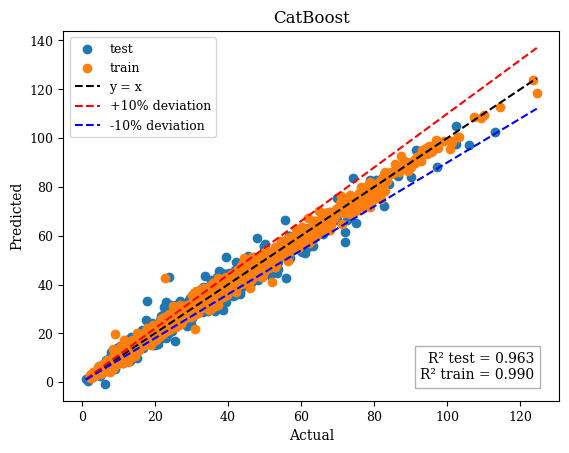

In [35]:
# Comparison of actual and predicted values for both training and testing datasets.


final_model = model_CatBoostRegressor
y_pred = final_model.predict(X_test)

r2_test = r2_score(y_test, y_CatBoostRegressor)
r2_train = r2_score(y_train, final_model.predict(X_train))

plt.scatter(y_test, y_pred, label='test')
plt.scatter(y_train, final_model.predict(X_train), label='train')

min_val = min(min(y_test), min(y_train))
max_val = max(max(y_test), max(y_train))
x_vals = np.linspace(min_val, max_val, 100)

plt.plot(x_vals, x_vals, 'k--', label='y = x')

plt.plot(x_vals, x_vals * 1.10, 'r--', label='+10% deviation')
plt.plot(x_vals, x_vals * 0.90, 'b--', label='-10% deviation')

textstr = f'R² test = {r2_test:.3f}\nR² train = {r2_train:.3f}'
plt.text(0.95, 0.05, textstr, transform=plt.gca().transAxes,
         fontsize=10, verticalalignment='bottom', horizontalalignment='right',
         bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray'))

plt.legend()
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('CatBoost')
plt.show()

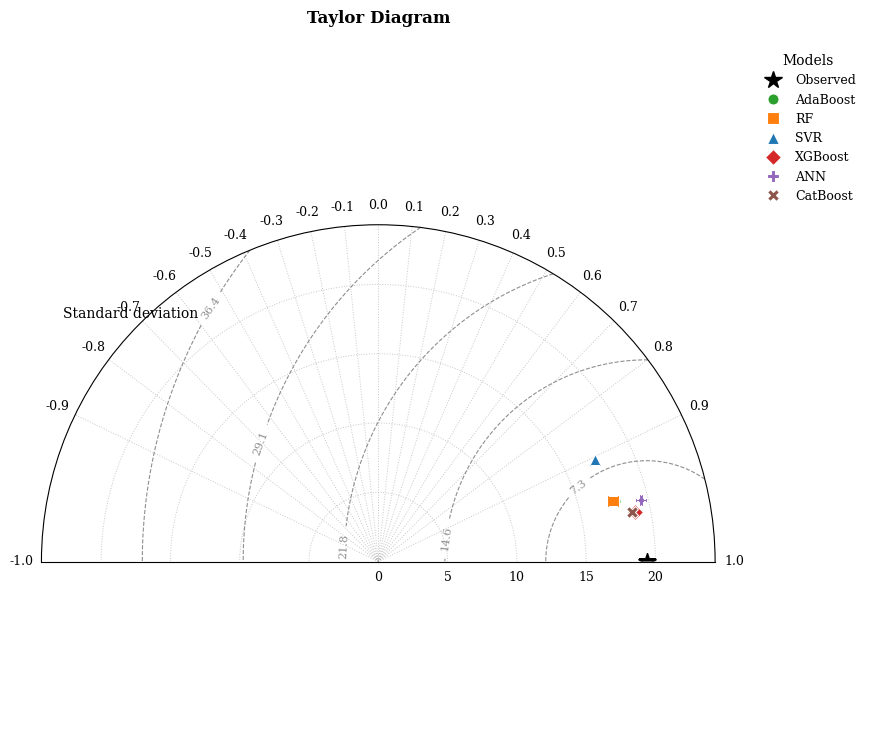

In [38]:

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Prepare observed and predicted values
# --------------------------------------------------
y_obs = np.asarray(y_test, dtype=float).ravel()

predictions = {
    "AdaBoost": np.asarray(y_AdaBoostRegressor, dtype=float).ravel(),
    "RF": np.asarray(y_RandomForestRegressor, dtype=float).ravel(),
    "SVR": np.asarray(y_SVR, dtype=float).ravel(),
    "XGBoost": np.asarray(y_XGBRegressor, dtype=float).ravel(),
    "ANN": np.asarray(y_MLPRegressor, dtype=float).ravel(),
    "CatBoost": np.asarray(y_CatBoostRegressor, dtype=float).ravel()
}

# Ensure all arrays refer to the same observations
for name, pred in predictions.items():
    if len(pred) != len(y_obs):
        raise ValueError(
            f"{name}: prediction length does not match y_test."
        )

# Remove observations with missing or infinite values consistently
valid = np.isfinite(y_obs)
for pred in predictions.values():
    valid &= np.isfinite(pred)

y_obs = y_obs[valid]
predictions = {
    name: pred[valid] for name, pred in predictions.items()
}

if len(y_obs) < 2:
    raise ValueError("At least two valid observations are required.")

# Use the same standard-deviation convention throughout
ref_std = np.std(y_obs, ddof=0)

if ref_std == 0:
    raise ValueError("The observed values have zero standard deviation.")

# Compute statistics for every model
stats = {}
for name, pred in predictions.items():
    if np.std(pred, ddof=0) == 0:
        corr = np.nan
    else:
        corr = np.corrcoef(y_obs, pred)[0, 1]

    stats[name] = {
        "std": np.std(pred, ddof=0),
        "corr": corr
    }

# --------------------------------------------------
# Taylor Diagram
# Supports positive and negative correlations
# --------------------------------------------------
class TaylorDiagram:
    def __init__(self, refstd, fig=None, rect=111,
                 label="Observed", rmax=None):

        self.refstd = refstd
        self.rmax = rmax if rmax is not None else 1.5 * refstd

        if fig is None:
            fig = plt.figure(figsize=(8.5, 7))

        self.fig = fig
        self.ax = fig.add_subplot(rect, polar=True)

        # Angle: arccos(correlation)
        self.ax.set_thetamin(0)
        self.ax.set_thetamax(180)
        self.ax.set_ylim(0, self.rmax)

        # Correlation labels from -1 to +1
        correlations = np.array([
            1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4,
            0.3, 0.2, 0.1, 0.0, -0.1, -0.2,
            -0.3, -0.4, -0.5, -0.6, -0.7,
            -0.8, -0.9, -1.0
        ])

        angles = np.degrees(np.arccos(correlations))
        self.ax.set_thetagrids(
            angles,
            labels=[f"{r:.1f}" for r in correlations]
        )
        self.ax.set_rlabel_position(135)

        self.ax.set_title(
            "Taylor Diagram",
            pad=24,
            fontweight="semibold"
        )

        self.ax.plot(
            0, refstd,
            marker="*",
            markersize=13,
            color="black",
            linestyle="None",
            label=label,
            zorder=5
        )

        self.ax.text(
            np.radians(135),
            self.rmax * 1.04,
            "Standard deviation",
            ha="center",
            va="center",
            fontsize=10
        )

    def add_sample(self, stddev, corrcoef, label,
                   marker="o", color="tab:blue"):

        if not np.isfinite(corrcoef):
            return

        corrcoef = np.clip(corrcoef, -1.0, 1.0)
        theta = np.arccos(corrcoef)

        self.ax.plot(
            theta, stddev,
            marker=marker,
            linestyle="None",
            markersize=8,
            markerfacecolor=color,
            markeredgecolor="white",
            markeredgewidth=0.8,
            label=label,
            zorder=4
        )

    def add_contours(self, levels=6):
        # Centered RMSE:
        # CRMSE^2 = refstd^2 + stddev^2
        #           - 2*refstd*stddev*correlation
        theta = np.linspace(0, np.pi, 240)
        radius = np.linspace(0, self.rmax, 220)
        T, R = np.meshgrid(theta, radius)

        crmse = np.sqrt(
            np.maximum(
                self.refstd**2 + R**2
                - 2 * self.refstd * R * np.cos(T),
                0
            )
        )

        contour_levels = np.linspace(
            0, np.nanmax(crmse), levels + 1
        )[1:]

        contours = self.ax.contour(
            T, R, crmse,
            levels=contour_levels,
            colors="0.45",
            linewidths=0.8,
            linestyles="dashed",
            alpha=0.8
        )

        self.ax.clabel(
            contours,
            inline=True,
            fontsize=8,
            fmt="%.1f"
        )

        return contours


# --------------------------------------------------
# Create publication-quality figure
# --------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

max_std = max(
    [ref_std] + [s["std"] for s in stats.values()]
)
rmax = max_std * 1.25

fig = plt.figure(figsize=(9, 7.5))
dia = TaylorDiagram(
    ref_std,
    fig=fig,
    label="Observed",
    rmax=rmax
)

dia.add_contours(levels=6)

colors = {
    "AdaBoost": "tab:green",
    "RF": "tab:orange",
    "SVR": "tab:blue",
    "XGBoost": "tab:red",
    "ANN": "tab:purple",
    "CatBoost": "tab:brown"
}

markers = ["o", "s", "^", "D", "P", "X"]

for i, (name, values) in enumerate(stats.items()):
    dia.add_sample(
        stddev=values["std"],
        corrcoef=values["corr"],
        label=name,
        marker=markers[i % len(markers)],
        color=colors[name]
    )

dia.ax.grid(True, linestyle=":", linewidth=0.7, alpha=0.7)

dia.ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.05, 1.02),
    frameon=False,
    title="Models"
)

fig.tight_layout()

fig.savefig(
    "Figure_Taylor_Diagram.png",
    dpi=600,
    bbox_inches="tight"
)
fig.savefig(
    "Figure_Taylor_Diagram.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

In [39]:

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ============================================================
# 1. Obtain REAL predictions on the same independent test set
# ============================================================
# Required existing objects:
# X_test, y_test, models
#
models = {
    "AdaBoost": model_AdaBoostRegressor,
    "RF": model_RandomForestRegressor,
    "SVR": model_SVR,
    "XGBoost": model_XGBRegressor,
    "ANN": model_MLPRegressor,
    "CatBoost": model_CatBoostRegressor
}

y_true = np.asarray(y_test, dtype=float).ravel()

predictions = {}
for name, model in models.items():
    predictions[name] = np.asarray(
        model.predict(X_test), dtype=float
    ).ravel()

# Check alignment and remove invalid rows consistently
valid = np.isfinite(y_true)
for pred in predictions.values():
    if len(pred) != len(y_true):
        raise ValueError("Prediction lengths do not match y_test.")
    valid &= np.isfinite(pred)

y_true = y_true[valid]
predictions = {
    name: pred[valid] for name, pred in predictions.items()
}

if len(y_true) < 2:
    raise ValueError("Not enough valid test observations.")

model_names = list(predictions.keys())
reference_model = "XGBoost"

if reference_model not in predictions:
    raise ValueError("A model named 'XGBoost' is required.")

print("Number of independent test observations:", len(y_true))

# ============================================================
# 2. Observed performance metrics
# ============================================================
def calculate_metrics(y, pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "MAE": mean_absolute_error(y, pred),
        "R2": 1 - np.sum((y - pred) ** 2)
              / np.sum((y - np.mean(y)) ** 2)
    }

metric_rows = []
for name, pred in predictions.items():
    row = {"Model": name}
    row.update(calculate_metrics(y_true, pred))
    metric_rows.append(row)

metrics_df = pd.DataFrame(metric_rows).set_index("Model")

print("\n=== Test-set performance ===")
print(metrics_df.round(4).to_string())

# ============================================================
# 3. Paired bootstrap confidence intervals
#    for each model's RMSE and MAE
# ============================================================
rng = np.random.default_rng(42)
n_bootstrap = 5000
n = len(y_true)

bootstrap_rows = []

for name, pred in predictions.items():
    boot_rmse = np.empty(n_bootstrap)
    boot_mae = np.empty(n_bootstrap)

    for b in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)
        err = y_true[idx] - pred[idx]
        boot_rmse[b] = np.sqrt(np.mean(err ** 2))
        boot_mae[b] = np.mean(np.abs(err))

    bootstrap_rows.append({
        "Model": name,
        "RMSE": metrics_df.loc[name, "RMSE"],
        "RMSE_CI_lower": np.percentile(boot_rmse, 2.5),
        "RMSE_CI_upper": np.percentile(boot_rmse, 97.5),
        "MAE": metrics_df.loc[name, "MAE"],
        "MAE_CI_lower": np.percentile(boot_mae, 2.5),
        "MAE_CI_upper": np.percentile(boot_mae, 97.5)
    })

ci_df = pd.DataFrame(bootstrap_rows).set_index("Model")

print("\n=== 95% bootstrap confidence intervals ===")
print(ci_df.round(4).to_string())

# ============================================================
# 4. Paired tests against XGBoost
#
# Tests are performed on paired per-observation losses:
#   MAE comparison: absolute errors
#   MSE comparison: squared errors
#
# Lower loss is better.
# ============================================================
ref_pred = predictions[reference_model]
ref_abs_error = np.abs(y_true - ref_pred)
ref_sq_error = (y_true - ref_pred) ** 2

test_rows = []

for name, pred in predictions.items():
    if name == reference_model:
        continue

    abs_error = np.abs(y_true - pred)
    sq_error = (y_true - pred) ** 2

    # Positive improvement means XGBoost has lower loss
    mae_improvement = np.mean(abs_error - ref_abs_error)
    mse_improvement = np.mean(sq_error - ref_sq_error)

    # Paired t-test on absolute losses
    t_mae, p_t_mae = stats.ttest_rel(
        abs_error, ref_abs_error
    )

    # Wilcoxon signed-rank test on absolute losses
    try:
        w_mae, p_w_mae = stats.wilcoxon(
            abs_error,
            ref_abs_error,
            alternative="two-sided",
            zero_method="wilcox"
        )
    except ValueError:
        w_mae, p_w_mae = np.nan, np.nan

    # Paired t-test on squared losses
    t_mse, p_t_mse = stats.ttest_rel(
        sq_error, ref_sq_error
    )

    # Wilcoxon test on squared losses
    try:
        w_mse, p_w_mse = stats.wilcoxon(
            sq_error,
            ref_sq_error,
            alternative="two-sided",
            zero_method="wilcox"
        )
    except ValueError:
        w_mse, p_w_mse = np.nan, np.nan

    # Relative improvements based on observed metrics
    other_rmse = metrics_df.loc[name, "RMSE"]
    xgb_rmse = metrics_df.loc[reference_model, "RMSE"]
    other_mae = metrics_df.loc[name, "MAE"]
    xgb_mae = metrics_df.loc[reference_model, "MAE"]

    rmse_reduction_pct = (
        100 * (other_rmse - xgb_rmse) / other_rmse
        if other_rmse != 0 else np.nan
    )
    mae_reduction_pct = (
        100 * (other_mae - xgb_mae) / other_mae
        if other_mae != 0 else np.nan
    )

    test_rows.append({
        "Model": name,
        "MAE_reduction_pct": mae_reduction_pct,
        "RMSE_reduction_pct": rmse_reduction_pct,
        "Mean_abs_loss_diff": mae_improvement,
        "Paired_t_p_MAE": p_t_mae,
        "Wilcoxon_p_MAE": p_w_mae,
        "Mean_squared_loss_diff": mse_improvement,
        "Paired_t_p_squared_loss": p_t_mse,
        "Wilcoxon_p_squared_loss": p_w_mse
    })

tests_df = pd.DataFrame(test_rows).set_index("Model")

# ============================================================
# 5. Holm correction for multiple comparisons
# ============================================================
def holm_adjust(p_values):
    """Holm-Bonferroni adjusted p-values; preserves NaNs."""
    p = np.asarray(p_values, dtype=float)
    adjusted = np.full(p.shape, np.nan)
    valid_idx = np.where(np.isfinite(p))[0]

    if len(valid_idx) == 0:
        return adjusted

    pv = p[valid_idx]
    order = np.argsort(pv)
    sorted_p = pv[order]
    m = len(sorted_p)

    sorted_adj = np.maximum.accumulate(
        (m - np.arange(m)) * sorted_p
    )
    sorted_adj = np.minimum(sorted_adj, 1.0)

    unsorted_adj = np.empty(m)
    unsorted_adj[order] = sorted_adj
    adjusted[valid_idx] = unsorted_adj

    return adjusted

for col in [
    "Paired_t_p_MAE",
    "Wilcoxon_p_MAE",
    "Paired_t_p_squared_loss",
    "Wilcoxon_p_squared_loss"
]:
    tests_df[col + "_Holm"] = holm_adjust(tests_df[col].values)

print("\n=== Pairwise comparisons against XGBoost ===")
print(tests_df.round(5).to_string())

print("\nInterpretation:")
print("For each test, use the Holm-adjusted p-value.")
print("Adjusted p < 0.05 indicates statistical significance at alpha=0.05.")
print("These tests compare per-observation losses, not signed residuals.")

# ============================================================
# 6. Paired bootstrap CI for difference in MAE and RMSE
#    Difference = competitor metric - XGBoost metric.
#    Positive difference favors XGBoost.
# ============================================================
rng = np.random.default_rng(123)
n_bootstrap_diff = 5000
difference_rows = []

for name, pred in predictions.items():
    if name == reference_model:
        continue

    mae_diff_boot = np.empty(n_bootstrap_diff)
    rmse_diff_boot = np.empty(n_bootstrap_diff)

    for b in range(n_bootstrap_diff):
        idx = rng.integers(0, n, size=n)

        err_comp = y_true[idx] - pred[idx]
        err_ref = y_true[idx] - ref_pred[idx]

        mae_diff_boot[b] = (
            np.mean(np.abs(err_comp))
            - np.mean(np.abs(err_ref))
        )

        rmse_diff_boot[b] = (
            np.sqrt(np.mean(err_comp ** 2))
            - np.sqrt(np.mean(err_ref ** 2))
        )

    mae_diff = (
        metrics_df.loc[name, "MAE"]
        - metrics_df.loc[reference_model, "MAE"]
    )
    rmse_diff = (
        metrics_df.loc[name, "RMSE"]
        - metrics_df.loc[reference_model, "RMSE"]
    )

    difference_rows.append({
        "Model": name,
        "MAE_difference": mae_diff,
        "MAE_diff_CI_lower": np.percentile(mae_diff_boot, 2.5),
        "MAE_diff_CI_upper": np.percentile(mae_diff_boot, 97.5),
        "RMSE_difference": rmse_diff,
        "RMSE_diff_CI_lower": np.percentile(rmse_diff_boot, 2.5),
        "RMSE_diff_CI_upper": np.percentile(rmse_diff_boot, 97.5)
    })

difference_df = pd.DataFrame(difference_rows).set_index("Model")

print("\n=== Paired bootstrap CIs for differences vs XGBoost ===")
print("Positive differences favor XGBoost; negative differences favor the competitor.")
print(difference_df.round(4).to_string())

# ============================================================
# 7. Export results for the manuscript
# ============================================================
metrics_df.to_csv("test_set_metrics.csv")
ci_df.to_csv("test_set_metric_confidence_intervals.csv")
tests_df.to_csv("paired_tests_vs_XGBoost.csv")
difference_df.to_csv("paired_bootstrap_differences_vs_XGBoost.csv")

print("\nResults saved to CSV files.")

Number of independent test observations: 536

=== Test-set performance ===
            RMSE     MAE      R2
Model                           
AdaBoost  4.9426  3.5756  0.9349
RF        4.9868  3.5352  0.9337
SVR       8.2392  6.2998  0.8190
XGBoost   3.6988  2.6394  0.9635
ANN       4.4779  3.0699  0.9465
CatBoost  3.7028  2.7185  0.9634

=== 95% bootstrap confidence intervals ===
            RMSE  RMSE_CI_lower  RMSE_CI_upper     MAE  MAE_CI_lower  MAE_CI_upper
Model                                                                             
AdaBoost  4.9426         4.4134         5.5169  3.5756        3.2863        3.8774
RF        4.9868         4.4896         5.5108  3.5352        3.2440        3.8410
SVR       8.2392         7.6345         8.8335  6.2998        5.8456        6.7541
XGBoost   3.6988         3.3216         4.1148  2.6394        2.4225        2.8596
ANN       4.4779         4.0542         4.8832  3.0699        2.8011        3.3505
CatBoost  3.7028         3.3804     


========== MODEL ERROR METRICS ==========
             MAE    RMSE      MSE
Model                            
AdaBoost  3.5756  4.9426  24.4292
RF        3.5352  4.9868  24.8679
SVR       6.2998  8.2392  67.8840
XGBoost   2.6394  3.6988  13.6811
ANN       3.0699  4.4779  20.0513
CatBoost  2.7185  3.7028  13.7111

====== ERROR REDUCTION RELATIVE TO XGBOOST ======
                MAE reduction (%)  RMSE reduction (%)  MSE reduction (%)
Compared model                                                          
AdaBoost                    26.18               25.16              44.00
RF                          25.34               25.83              44.98
SVR                         58.10               55.11              79.85
ANN                         14.02               17.40              31.77
CatBoost                     2.91                0.11               0.22


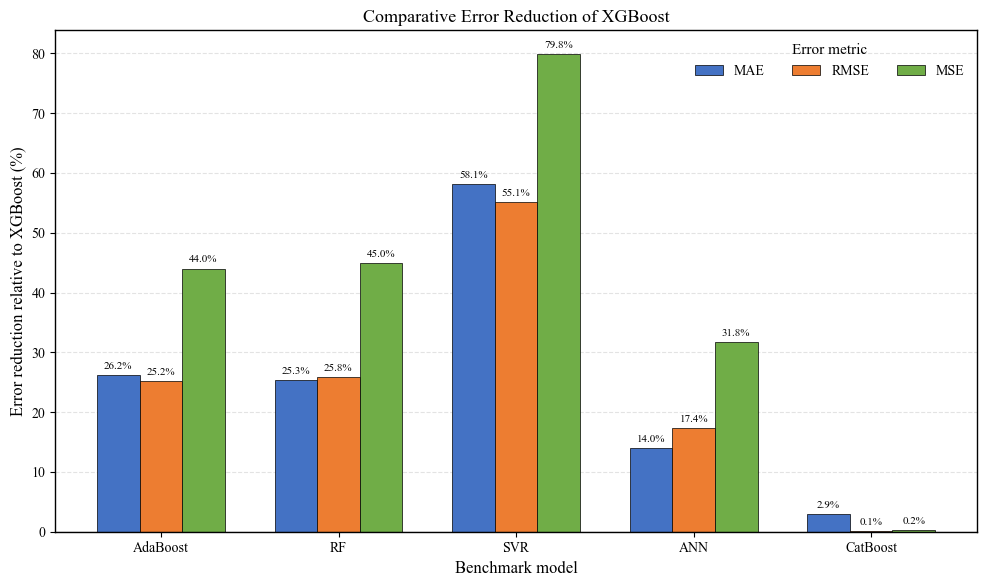

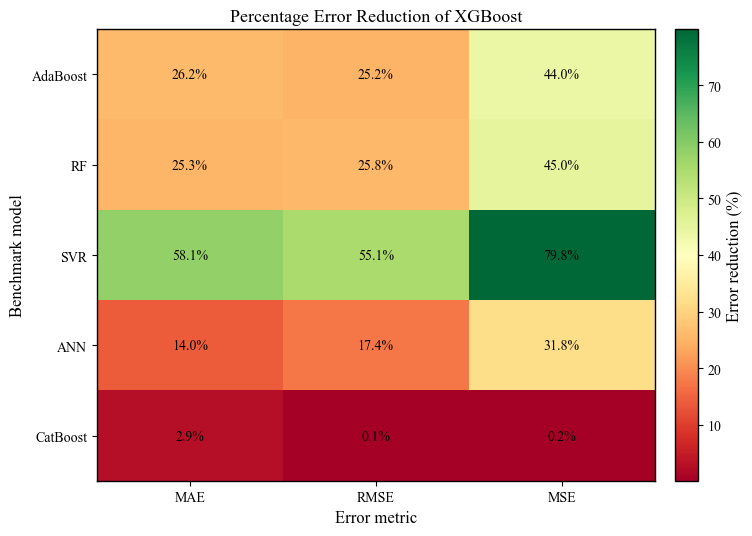


========== MANUSCRIPT SUMMARY ==========

XGBoost vs. AdaBoost
  MAE: 26.18% reduction
  RMSE: 25.16% reduction
  MSE: 44.00% reduction

XGBoost vs. RF
  MAE: 25.34% reduction
  RMSE: 25.83% reduction
  MSE: 44.98% reduction

XGBoost vs. SVR
  MAE: 58.10% reduction
  RMSE: 55.11% reduction
  MSE: 79.85% reduction

XGBoost vs. ANN
  MAE: 14.02% reduction
  RMSE: 17.40% reduction
  MSE: 31.77% reduction

XGBoost vs. CatBoost
  MAE: 2.91% reduction
  RMSE: 0.11% reduction
  MSE: 0.22% reduction

Files saved:
- model_error_metrics.csv
- XGBoost_error_reduction.csv
- Figure_Error_Reduction_BarChart.png/.tiff
- Figure_Error_Reduction_Heatmap.png/.tiff


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# ============================================================
# 1. Journal-style plotting settings
# ============================================================
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.linewidth": 1.0,
    "savefig.dpi": 600,
    "savefig.bbox": "tight"
})

# ============================================================
# 2. Obtain predictions on the same test set
# ============================================================
# Required:
# X_test, y_test
# models = {
#     "AdaBoost": fitted_model,
#     "RF": fitted_model,
#     "SVR": fitted_model,
#     "XGBoost": fitted_model,
#     "ANN": fitted_model,
#     "CatBoost": fitted_model
# }

proposed_model = "XGBoost"

if proposed_model not in models:
    raise ValueError("XGBoost must be present in the models dictionary.")

y_true = np.asarray(y_test, dtype=float).ravel()

predictions = {
    name: np.asarray(model.predict(X_test), dtype=float).ravel()
    for name, model in models.items()
}

if any(len(p) != len(y_true) for p in predictions.values()):
    raise ValueError("Prediction lengths do not match y_test.")

# Use the same valid observations for every model
valid = np.isfinite(y_true)
for pred in predictions.values():
    valid &= np.isfinite(pred)

y_true = y_true[valid]
predictions = {
    name: pred[valid] for name, pred in predictions.items()
}

if len(y_true) == 0:
    raise ValueError("No valid test observations.")

# ============================================================
# 3. Calculate MAE, RMSE, and MSE
# ============================================================
metric_results = []

for name, pred in predictions.items():
    mae = mean_absolute_error(y_true, pred)

    mse = mean_squared_error(y_true, pred)

    rmse = np.sqrt(mse)

    metric_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MSE": mse
    })

metrics_df = pd.DataFrame(metric_results).set_index("Model")

print("\n========== MODEL ERROR METRICS ==========")
print(metrics_df.round(4).to_string())

# ============================================================
# 4. Percentage error reduction relative to competitors
# ============================================================
# Reduction (%) = (Competitor error - XGBoost error)
#                 / Competitor error * 100
#
# Positive: XGBoost has lower error.
# Negative: XGBoost has higher error.

competitors = [
    name for name in metrics_df.index
    if name != proposed_model
]

error_metrics = ["MAE", "RMSE", "MSE"]

reduction_results = []

for name in competitors:
    row = {"Compared model": name}

    for metric in error_metrics:
        competitor_error = metrics_df.loc[name, metric]
        proposed_error = metrics_df.loc[proposed_model, metric]

        if competitor_error == 0:
            reduction = np.nan
        else:
            reduction = (
                (competitor_error - proposed_error)
                / competitor_error
            ) * 100

        row[f"{metric} reduction (%)"] = reduction

    reduction_results.append(row)

reduction_df = pd.DataFrame(
    reduction_results
).set_index("Compared model")

print("\n====== ERROR REDUCTION RELATIVE TO XGBOOST ======")
print(reduction_df.round(2).to_string())

# Save numerical results
metrics_df.to_csv("model_error_metrics.csv")
reduction_df.to_csv("XGBoost_error_reduction.csv")

# ============================================================
# 5. Figure 1: Grouped bar chart of error reductions
# ============================================================
plot_df = reduction_df[
    [
        "MAE reduction (%)",
        "RMSE reduction (%)",
        "MSE reduction (%)"
    ]
].copy()

# Standardize column names for easier plot labels
plot_df.columns = ["MAE", "RMSE", "MSE"]

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(plot_df.index))
width = 0.24

colors = ["#4472C4", "#ED7D31", "#70AD47"]

for i, metric in enumerate(["MAE", "RMSE", "MSE"]):
    values = plot_df[metric].to_numpy(dtype=float)

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width=width,
        label=metric,
        color=colors[i],
        edgecolor="black",
        linewidth=0.5
    )

    # Label bars with percentages
    for bar, value in zip(bars, values):
        if np.isfinite(value):
            ax.annotate(
                f"{value:.1f}%",
                (bar.get_x() + bar.get_width() / 2, value),
                xytext=(0, 3 if value >= 0 else -3),
                textcoords="offset points",
                ha="center",
                va="bottom" if value >= 0 else "top",
                fontsize=8,
                rotation=0
            )

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=0)
ax.set_xlabel("Benchmark model")
ax.set_ylabel("Error reduction relative to XGBoost (%)")
ax.set_title("Comparative Error Reduction of XGBoost")
ax.legend(title="Error metric", frameon=False, ncol=3)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("Figure_Error_Reduction_BarChart.png", dpi=600)
plt.savefig("Figure_Error_Reduction_BarChart.tiff", dpi=600)
plt.show()

# ============================================================
# 6. Figure 2: Heatmap of percentage error reductions
# ============================================================
heat_data = plot_df.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(8, 5.5))

im = ax.imshow(
    heat_data,
    cmap="RdYlGn",
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(np.arange(len(plot_df.columns)))
ax.set_xticklabels(plot_df.columns)

ax.set_yticks(np.arange(len(plot_df.index)))
ax.set_yticklabels(plot_df.index)

for i in range(heat_data.shape[0]):
    for j in range(heat_data.shape[1]):
        value = heat_data[i, j]
        label = f"{value:.1f}%" if np.isfinite(value) else "N/A"

        ax.text(
            j, i, label,
            ha="center", va="center",
            fontsize=10, color="black"
        )

ax.set_title("Percentage Error Reduction of XGBoost")
ax.set_xlabel("Error metric")
ax.set_ylabel("Benchmark model")

cbar = fig.colorbar(im, ax=ax, pad=0.03)
cbar.set_label("Error reduction (%)")

plt.tight_layout()
plt.savefig("Figure_Error_Reduction_Heatmap.png", dpi=600)
plt.savefig("Figure_Error_Reduction_Heatmap.tiff", dpi=600)
plt.show()

# ============================================================
# 7. Print a manuscript-ready summary
# ============================================================
print("\n========== MANUSCRIPT SUMMARY ==========")

for name in competitors:
    print(f"\nXGBoost vs. {name}")

    for metric in ["MAE", "RMSE", "MSE"]:
        value = reduction_df.loc[
            name, f"{metric} reduction (%)"
        ]

        if pd.isna(value):
            print(f"  {metric}: undefined")
        elif value > 0:
            print(f"  {metric}: {value:.2f}% reduction")
        elif value < 0:
            print(f"  {metric}: {abs(value):.2f}% higher error")
        else:
            print(f"  {metric}: no change")

print("\nFiles saved:")
print("- model_error_metrics.csv")
print("- XGBoost_error_reduction.csv")
print("- Figure_Error_Reduction_BarChart.png/.tiff")
print("- Figure_Error_Reduction_Heatmap.png/.tiff")